# 05 · Fase e capacitância na classificação de VEs no E7

Comparamos seis classificadores nas mesmas 30 aplicações históricas, com 15 gotas por linhagem. Cada ajuste recebe sete atributos de uma única representação. O desfecho é a linhagem MCF10A ou HCC1806.

[Nicoliche et al. (2020)](https://doi.org/10.1021/acssensors.0c00599) usaram medidas de capacitância diferencial em um sensor de grafite e aplicaram o SISSO para estimar concentrações de VEs e de proteínas. Neste E7, usamos capacitância paralela equivalente normalizada pelo PBS local, como descrito na monografia. A comparação mantém o mesmo número de atributos e o mesmo pareamento com PBS nas duas condições.

In [1]:
from pathlib import Path
import sys
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import LeaveOneGroupOut, LeaveOneOut
from sklearn.naive_bayes import GaussianNB

RAIZ = Path.cwd()
PACOTE = RAIZ / 'TCC_EIS_Modelos_Basicos'
assert (PACOTE / 'dados').is_dir(), 'Abra o notebook na pasta raiz do projeto.'
sys.path.insert(0, str(PACOTE))
from eis_utils import FREQUENCY, band_average, read_all
from modelos_basicos import basic_models, cv_predictions
from sisso_oficial import CLASSES, ROTULO_SISSO, localizar_sisso, prever_sisso

HISTORICO = PACOTE / 'dados' / 'Medicoes_EIS_Por_Dispositivo_ATUALIZADO_E02.zip'
PASTA_FIGURAS = RAIZ / 'imagens_prontas_capacitancia'
PASTA_FIGURAS.mkdir(exist_ok=True)
BORDAS = [.1, 1, 10, 100, 1_000, 10_000, 100_000, 1_000_000]
BANDAS = list(zip(BORDAS, BORDAS[1:]))
ATRIBUTOS = [f'F_b{i}' for i in range(1, len(BORDAS))]
ETAPAS = {
    'OLD': '01_Campanha_inicial', 'T': '03_T01-T08',
    'V2': '04_Treinamento_V2', 'V3': '05_Validacao_V3',
}
df = pd.read_csv(PACOTE / 'dados' / 'E7_30_aplicacoes_historicas_caracteristicas.csv',
                 usecols=['id', 'campanha', 'bloco', 'classe', *ATRIBUTOS])
y = df.classe.to_numpy()
y_binario = df.classe.eq('HCC1806').to_numpy(dtype=int)
X_fase = df[ATRIBUTOS].to_numpy(float)
assert X_fase.shape == (30, 7) and np.isfinite(X_fase).all() and df.id.is_unique
assert df.classe.value_counts().to_dict() == dict.fromkeys(CLASSES, 15)
assert df.campanha.nunique() == 4 and df.bloco.nunique() == 8
assert df.groupby('bloco').campanha.nunique().eq(1).all()

## Sete atributos de cada representação

- **Fase.** Média por banda de $\overline{(-\phi)}_{\mathrm{VE}}-\overline{(-\phi)}_{\mathrm{PBS}}$, com médias das triplicatas em cada frequência. A coluna −Phase segue a convenção dos arquivos de EIS.
- **Capacitância.** Calculamos $C_p(f)=\operatorname{Im}(1/Z)/(2\pi f)=-Z''/(2\pi f[(Z')^2+(Z'')^2])$ em cada frequência e leitura. Usamos a média das três capacitâncias para a gota e para seu PBS local. O atributo é a média por banda de $100\ln(\overline{C}_{p,\mathrm{VE}}/\overline{C}_{p,\mathrm{PBS}})$. O fator 100 expressa a razão logarítmica numa escala próxima a uma variação percentual quando a razão está próxima de 1.

Em ambas as condições usamos as mesmas sete bandas de 0,1 Hz a 1 MHz e o pareamento por número dentro da campanha. A fase recalculada é conferida com a tabela usada no notebook 03. A capacitância descreve a resposta equivalente do sistema medido no eletrodo.

In [2]:
def media_em_bandas(frequencia, valores):
    return [band_average(frequencia, valores, inferior, superior)
            for inferior, superior in BANDAS]


def capacitancia_da_gota(arquivo, gota):
    assert len(gota.files) == 3
    capacitancias = []
    for nome in gota.files:
        with arquivo.open(nome) as bruto:
            d = pd.read_csv(bruto).sort_values(FREQUENCY)
        freq = d[FREQUENCY].to_numpy(float)
        real = d["Z' (Ω)"].to_numpy(float)
        menos_imag = d["-Z'' (Ω)"].to_numpy(float)
        assert np.array_equal(freq, gota.f) and (freq > 0).all(), nome
        cp = menos_imag / (2 * np.pi * freq * (real**2 + menos_imag**2))
        assert np.isfinite(cp).all() and (cp > 0).all(), nome
        capacitancias.append(cp)
    return np.mean(capacitancias, axis=0)


espectros = read_all(HISTORICO).query("electrode == 'E07'")
fase_recalculada, capacitancia = [], []
with zipfile.ZipFile(HISTORICO) as arquivo:
    for r in df.itertuples(index=False):
        etapa = espectros[espectros.folder.str.endswith(ETAPAS[r.campanha])]
        id_gota = r.id.rsplit('_', 1)[-1]
        ves, = etapa[etapa.filename.str.contains(rf'(?:^|_){id_gota}_')].itertuples()
        pbs, = etapa[etapa.filename.str.contains(rf'(?:^|_)P{id_gota[1:]}_')].itertuples()
        assert ves.n_scans == pbs.n_scans == 3 and len(ves.f) == 71
        assert np.array_equal(ves.f, pbs.f), r.id
        fase_recalculada.append(media_em_bandas(ves.f, ves.p.mean(axis=0) - pbs.p.mean(axis=0)))
        cp_ves, cp_pbs = (capacitancia_da_gota(arquivo, gota) for gota in (ves, pbs))
        capacitancia.append(media_em_bandas(ves.f, 100 * np.log(cp_ves / cp_pbs)))

np.testing.assert_allclose(fase_recalculada, X_fase, atol=1e-10, rtol=0)
X_cap = np.asarray(capacitancia)
assert X_cap.shape == X_fase.shape and np.isfinite(X_cap).all()
REPRESENTACOES = {'Fase': X_fase, 'Capacitância': X_cap}
print('30 pares de VEs e PBS em triplicata · sete atributos por representação.')

30 pares de VEs e PBS em triplicata · sete atributos por representação.


## LOO, LOBO e LOCO

LOO exclui uma gota, LOBO exclui um bloco e LOCO exclui uma campanha inteira. A composição de cada divisão é idêntica para fase e capacitância. A função de validação reajusta cada modelo dentro do treino de cada divisão. A LDA usa o solver SVD padrão. O SISSO oficial 3.0.2 seleciona dois descritores por ajuste, seguidos do mesmo SVM linear com C=1 usado na análise de fase.

O gráfico reúne LOO, LOBO e LOCO em três painéis. Cada barra reúne uma previsão por aplicação histórica.

In [3]:
basicos = basic_models()
modelos = {nome: basicos[nome] for nome in ['Regressão logística', 'KNN (k=5)', 'Random Forest']}
modelos['Gaussian Naive Bayes'] = GaussianNB()
modelos['LDA'] = LinearDiscriminantAnalysis()
NOMES = [*modelos, ROTULO_SISSO]
VALIDACOES = {
    'LOO': (LeaveOneOut(), None),
    'LOBO': (LeaveOneGroupOut(), df.bloco.to_numpy()),
    'LOCO': (LeaveOneGroupOut(), df.campanha.to_numpy()),
}
particoes = {nome: list(divisor.split(X_fase, y, grupos))
             for nome, (divisor, grupos) in VALIDACOES.items()}
for nome, (_, grupos) in VALIDACOES.items():
    vistos = np.zeros(len(y), dtype=int)
    for treino, teste in particoes[nome]:
        assert not np.intersect1d(treino, teste).size
        if grupos is not None:
            assert set(grupos[treino]).isdisjoint(grupos[teste])
        vistos[teste] += 1
    assert (vistos == 1).all()

exe = localizar_sisso(RAIZ)


def avaliar_representacao(item):
    representacao, X = item
    linhas, descritores = [], []
    for validacao, (divisor, grupos) in VALIDACOES.items():
        for nome, modelo in modelos.items():
            pred = cv_predictions(X, y_binario, divisor, groups=grupos, model=modelo)
            linhas.append((representacao, validacao, nome, np.count_nonzero(pred == y_binario)))

        pred_sisso = np.empty(len(y), dtype=object)
        for treino, teste in particoes[validacao]:
            pred_sisso[teste], expressoes = prever_sisso(X[treino], y[treino], X[teste], exe)
            excluido = df.id.iloc[teste[0]] if grupos is None else grupos[teste[0]]
            descritores.append((representacao, validacao, excluido, *expressoes))
        assert np.isin(pred_sisso, CLASSES).all()
        linhas.append((representacao, validacao, ROTULO_SISSO, np.count_nonzero(pred_sisso == y)))
        print(f'{representacao} · {validacao} concluído.', flush=True)
    return linhas, descritores


avaliacoes = [avaliar_representacao(item) for item in REPRESENTACOES.items()]
resultado = pd.DataFrame(
    [linha for linhas, _ in avaliacoes for linha in linhas],
    columns=['Representação', 'Validação', 'Modelo', 'Acertos'],
)
assert len(resultado) == 36
assert not resultado.duplicated(['Representação', 'Validação', 'Modelo']).any()
resultado['Acurácia'] = resultado.Acertos / len(y)
tabela = resultado.pivot(index='Modelo', columns=['Validação', 'Representação'], values='Acertos')
tabela = tabela.reindex(index=NOMES, columns=pd.MultiIndex.from_product(
    [VALIDACOES, REPRESENTACOES], names=['Validação', 'Representação'],
))
fase_esperada = {
    'Regressão logística': [13, 17, 11], 'KNN (k=5)': [18, 22, 19],
    'Random Forest': [13, 18, 14], 'Gaussian Naive Bayes': [17, 16, 13],
    ROTULO_SISSO: [15, 14, 15],
}
for modelo, esperado in fase_esperada.items():
    assert tabela.loc[modelo].xs('Fase', level='Representação').tolist() == esperado
display(tabela.map(lambda n: f'{n}/{len(y)} ({100*n/len(y):.1f}%)'.replace('.', ',')))

descritores_sisso = pd.DataFrame(
    [linha for _, descritores in avaliacoes for linha in descritores],
    columns=['Representação', 'Validação', 'Grupo excluído', 'Descritor 1', 'Descritor 2'],
)
assert len(descritores_sisso) == 84
display(descritores_sisso[descritores_sisso['Validação'].eq('LOCO')])

Fase · LOO concluído.


Fase · LOBO concluído.


Fase · LOCO concluído.


Capacitância · LOO concluído.


Capacitância · LOBO concluído.


Capacitância · LOCO concluído.


Validação                           LOO                          LOBO  \
Representação                      Fase   Capacitância           Fase   
Modelo                                                                  
Regressão logística       13/30 (43,3%)   3/30 (10,0%)  17/30 (56,7%)   
KNN (k=5)                 18/30 (60,0%)  14/30 (46,7%)  22/30 (73,3%)   
Random Forest             13/30 (43,3%)   7/30 (23,3%)  18/30 (60,0%)   
Gaussian Naive Bayes      17/30 (56,7%)  11/30 (36,7%)  16/30 (53,3%)   
LDA                       14/30 (46,7%)   8/30 (26,7%)  16/30 (53,3%)   
SISSO 3.0.2 + SVM linear  15/30 (50,0%)  12/30 (40,0%)  14/30 (46,7%)   

Validação                                         LOCO                 
Representação              Capacitância           Fase   Capacitância  
Modelo                                                                 
Regressão logística       11/30 (36,7%)  11/30 (36,7%)  11/30 (36,7%)  
KNN (k=5)                 15/30 (50,0%)  19/30 (63,3%)  14/30 (46,7%)  
Random Forest             10/30 (33,3%)  14/30 (46,7%)  14/30 (46,7%)  
Gaussian Naive Bayes      13/30 (43,3%)  13/30 (43,3%)  16/30 (53,3%)  
LDA                       14/30 (46,7%)  15/30 (50,0%)  11/30 (36,7%)  
SISSO 3.0.2 + SVM linear  16/30 (53,3%)  15/30 (50,0%)  15/30 (50,0%)

,Representação,Validação,Grupo excluído,Descritor 1,Descritor 2
38,Fase,LOCO,OLD,(z1*z7),(z5-z6)
39,Fase,LOCO,T,(z1*z4),(z3+z4)
40,Fase,LOCO,V2,(z2*z7),(z2+z4)
41,Fase,LOCO,V3,(z1*z7),(z4-z7)
80,Capacitância,LOCO,OLD,(z5*z7),(z3*z4)
81,Capacitância,LOCO,T,(z1*z7),(z1*z6)
82,Capacitância,LOCO,V2,(z2*z3),(z3+z6)
83,Capacitância,LOCO,V3,(z5*z7),(z3*z4)


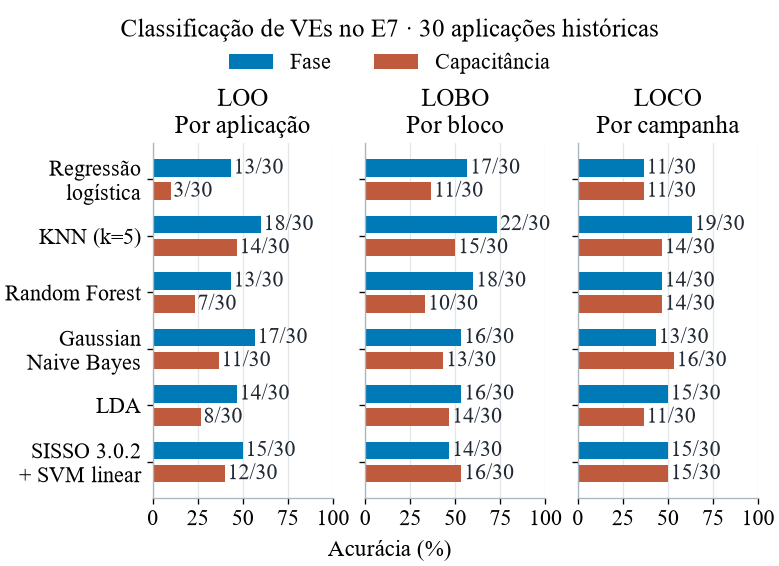

In [4]:
plt.rcParams.update({
    'font.family': 'Times New Roman', 'pdf.fonttype': 42,
    'figure.dpi': 120, 'font.size': 13, 'xtick.labelsize': 13, 'ytick.labelsize': 13,
    'axes.labelsize': 14, 'axes.titlesize': 15, 'figure.labelsize': 14,
    'legend.fontsize': 13, 'legend.title_fontsize': 15,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.axisbelow': True,
    'grid.color': '#D8DEE3', 'grid.alpha': .7, 'axes.edgecolor': '#ABB5BD',
    'figure.constrained_layout.use': True,
})
cores = {'Fase': '#0079B7', 'Capacitância': '#BF5A3C'}
titulos = {'LOO': 'LOO\nPor aplicação', 'LOBO': 'LOBO\nPor bloco',
           'LOCO': 'LOCO\nPor campanha'}
rotulos_modelos = {
    'Regressão logística': 'Regressão\nlogística',
    'Gaussian Naive Bayes': 'Gaussian\nNaive Bayes',
    'SISSO 3.0.2 + SVM linear': 'SISSO 3.0.2\n+ SVM linear',
}


def plotar_comparacao(validacoes, nome_pdf):
    fig, axs = plt.subplots(1, len(validacoes), figsize=(16.5 / 2.54, 12 / 2.54),
                           sharex=True, sharey=True, squeeze=False)
    posicoes = np.arange(len(NOMES))
    for ax, validacao in zip(axs[0], validacoes):
        for deslocamento, (representacao, cor) in zip([-.205, .205], cores.items()):
            acertos = tabela[validacao, representacao].to_numpy()
            barras = ax.barh(posicoes + deslocamento, acertos / len(y), height=.31, color=cor)
            for barra, n in zip(barras, acertos):
                y_barra = barra.get_y() + barra.get_height() / 2
                ax.text(n / len(y) + .015, y_barra, f'{n}/{len(y)}', va='center', color='#202934')
        ax.set(xlim=(0, 1), xticks=np.linspace(0, 1, 5), title=titulos[validacao])
        ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, symbol='', decimals=0))
        ax.set_yticks(posicoes, [rotulos_modelos.get(nome, nome) for nome in NOMES])
        ax.grid(axis='x')
    axs[0, 0].invert_yaxis()
    fig.supxlabel('Acurácia (%)')
    legenda = [Patch(facecolor=cor, label=nome) for nome, cor in cores.items()]
    fig.legend(handles=legenda, loc='outside upper center', ncol=2, frameon=False,
               title='Classificação de VEs no E7 · 30 aplicações históricas')
    fig.savefig(PASTA_FIGURAS / nome_pdf)
    plt.show()


plotar_comparacao(['LOO', 'LOBO', 'LOCO'], 'e7_fase_capacitancia_loo_lobo_loco.pdf')

## Como ler a comparação

Priorize o LOCO para discutir a transferência entre campanhas dentro do E7. Cada par de barras compara duas formas de representar os mesmos espectros. Os resultados são descritivos para as 30 gotas históricas.

Em LOCO, o KNN com fase atingiu o maior total da comparação (19/30). Com capacitância, o maior total foi do Gaussian Naive Bayes (16/30), que teve 13/30 com fase. A LDA passou de 15/30 com fase para 11/30 com capacitância. O SISSO + SVM linear obteve 15/30 em ambas as representações em LOCO e passou de 14/30 para 16/30 em LOBO. As diferenças variam por modelo e por divisão de validação.